In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu, chi2_contingency

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


## Loan Default Risk Prediction            

#### 1.Problem Understanding

#### 2.Business Problem
Lenders face financial losses when borrowers fail to repay loans. This project uses historical loan information to identify loans that may be at higher risk of default.

#### 3.Objective
Build and compare machine learning classification models to predict loan default, evaluate their performance using appropriate metrics, and identify useful risk indicators.

#### 4.Business Value
The analysis can support credit-risk assessment, portfolio monitoring, and further review of potentially risky applications. Predictions should support, not replace, responsible human decision-making.

#### 5.Evaluation Approach
The project will use a validation dataset, cross-validation, F1-score, precision, recall, ROC-AUC, and PR-AUC. It will also examine data leakage, class imbalance, feature importance, and limitations.

In [2]:
TRAIN_PATH = "loan_train.csv"
TEST_PATH = "loan_test.csv"
SAMPLE_PATH = "loan_sample_submission.csv"

if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(
        "Place loan_train.csv in the same folder as this notebook."
    )

train = pd.read_csv(TRAIN_PATH, low_memory=False)

test = (
    pd.read_csv(TEST_PATH, low_memory=False)
    if os.path.exists(TEST_PATH)
    else None
)

sample_submission = (
    pd.read_csv(SAMPLE_PATH, low_memory=False)
    if os.path.exists(SAMPLE_PATH)
    else None
)

print("Training shape:", train.shape)
print("Test shape:", test.shape if test is not None else "Not found")
print("Sample submission:", sample_submission.shape if sample_submission is not None else "Not found")

display(train.head())

Training shape: (27003, 47)
Test shape: (11574, 46)
Sample submission: (11574, 2)


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
0,540179,697401,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,...,11943.68,10000.00,1973.61,0.0,0.00,0.0,Sep-12,3536.63,Mar-14,0.0
1,585434,752191,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,...,15470.79,14000.00,1723.48,0.0,0.00,0.0,May-13,2603.31,Jan-16,0.0
2,457736,569298,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,...,10472.09,9475.00,997.09,0.0,0.00,0.0,May-11,5365.49,Aug-15,0.0
3,734349,930860,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,...,4425.26,4000.00,425.26,0.0,0.00,0.0,Jul-13,1336.22,May-15,0.0
4,1050080,1281522,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,...,2321.34,2004.17,306.88,0.0,10.29,0.0,Sep-13,110.54,May-16,0.0


## 1. Data Understanding

#### Inspect the training and test datasets, column names, data types, dataset dimensions, and summary statistics. This establishes what information is available before cleaning and modeling.

In [3]:
print("Column names:")
print(train.columns.tolist())

print("\nData types:")
display(train.dtypes.to_frame("Data Type"))

print("\nDataset information:")
train.info()

print("\nStatistical summary:")
display(train.describe(include="all").T)

print("\nRandom sample:")
display(train.sample(min(5, len(train)), random_state=RANDOM_STATE))

Column names:
['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'pub_rec_bankruptcies']

Data types:


,Data Type
id,int64
member_id,int64
loan_amnt,int64
funded_amnt,int64
funded_amnt_inv,float64
term,str
int_rate,str
installment,float64
grade,str
sub_grade,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 27003 entries, 0 to 27002
Data columns (total 47 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       27003 non-null  int64  
 1   member_id                27003 non-null  int64  
 2   loan_amnt                27003 non-null  int64  
 3   funded_amnt              27003 non-null  int64  
 4   funded_amnt_inv          27003 non-null  float64
 5   term                     27003 non-null  str    
 6   int_rate                 27003 non-null  str    
 7   installment              27003 non-null  float64
 8   grade                    27003 non-null  str    
 9   sub_grade                27003 non-null  str    
 10  emp_title                25321 non-null  str    
 11  emp_length               26273 non-null  str    
 12  home_ownership           27003 non-null  str    
 13  annual_inc               27003 non-null  float64
 14  verificatio

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,27003.0,NaN,NaN,NaN,676300.72566,209044.025722,54734.0,512663.0,657052.0,827101.5,1077430.0
member_id,27003.0,NaN,NaN,NaN,842247.267341,264254.127295,70699.0,661775.5,840072.0,1035237.5,1314167.0
loan_amnt,27003.0,NaN,NaN,NaN,11087.94671,7392.758683,500.0,5300.0,9750.0,15000.0,35000.0
funded_amnt,27003.0,NaN,NaN,NaN,10816.216717,7131.666342,500.0,5175.0,9600.0,15000.0,35000.0
funded_amnt_inv,27003.0,NaN,NaN,NaN,10251.064645,7066.203699,0.0,5000.0,8731.0261,14025.0,35000.0
term,27003,2,36 months,20382,NaN,NaN,NaN,NaN,NaN,NaN,NaN
int_rate,27003,368,10.99%,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
installment,27003.0,NaN,NaN,NaN,323.375002,209.866524,15.69,165.805,277.57,427.0,1302.69
grade,27003,7,B,8189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sub_grade,27003,35,A4,1985,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Random sample:


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
15786,697004,888234,4500,4500,4500.00000,36 months,12.68%,150.94,C,C1,...,5433.41,4500.0,933.41,0.0,0.0,0.0,Mar-14,172.13,Dec-15,0.0
13218,821024,1029281,11000,11000,10750.00000,36 months,6.99%,339.60,A,A3,...,11137.08,11000.0,396.08,0.0,0.0,0.0,Mar-12,8737.74,Sep-15,0.0
16431,857504,1069971,4000,4000,4000.00000,36 months,12.99%,134.76,C,C1,...,4743.73,4000.0,743.73,0.0,0.0,0.0,Sep-13,1650.27,Nov-15,0.0
4564,974970,1197062,12000,12000,12000.00000,36 months,7.51%,373.33,A,A3,...,13169.71,12000.0,1169.71,0.0,0.0,0.0,Jul-13,5712.25,Apr-15,0.0
11828,435969,521308,20000,20000,19522.10915,36 months,11.83%,662.68,B,B3,...,23179.65,20000.0,3761.07,0.0,0.0,0.0,May-12,88.50,Sep-12,0.0


## 2. Data Quality Assessment and Cleaning

#### Identify missing values and duplicates, normalize blank text values, and apply only defensible cleaning steps. Review the outputs to ensure cleaning has not removed meaningful information

In [4]:
missing = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percentage": train.isnull().mean().mul(100).round(2),
    "Data Type": train.dtypes.astype(str)
}).sort_values("Missing Percentage", ascending=False)

display(missing)

print("Duplicate rows:", train.duplicated().sum())

if "id" in train.columns:
    print("Duplicate loan IDs:", train["id"].duplicated().sum())

print("Constant columns:")
print([
    col for col in train.columns
    if train[col].nunique(dropna=False) <= 1
])

,Missing Count,Missing Percentage,Data Type
mths_since_last_record,25065,92.82,float64
mths_since_last_delinq,17395,64.42,float64
desc,8779,32.51,str
emp_title,1682,6.23,str
emp_length,730,2.70,str
pub_rec_bankruptcies,503,1.86,float64
last_pymnt_d,51,0.19,str
revol_util,35,0.13,str
title,9,0.03,str
int_rate,0,0.00,str


Duplicate rows: 0
Duplicate loan IDs: 0
Constant columns:
['out_prncp', 'out_prncp_inv']


In [5]:
train = train.copy()

train = train.drop_duplicates().reset_index(drop=True)

for col in train.select_dtypes(include=["object", "string"]).columns:
    train[col] = train[col].replace(r"^\s*$", np.nan, regex=True)
    train[col] = train[col].map(
        lambda x: x.strip() if isinstance(x, str) else x
    )

if test is not None:
    test = test.copy()
    for col in test.select_dtypes(include=["object", "string"]).columns:
        test[col] = test[col].replace(r"^\s*$", np.nan, regex=True)
        test[col] = test[col].map(
            lambda x: x.strip() if isinstance(x, str) else x
        )

print("Shape after duplicate removal:", train.shape)
print("Remaining duplicate rows:", train.duplicated().sum())
display(train.head())

Shape after duplicate removal: (27003, 47)
Remaining duplicate rows: 0


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_pymnt_inv,total_rec_prncp,total_rec_int,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,last_credit_pull_d,pub_rec_bankruptcies
0,540179,697401,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,...,11943.68,10000.00,1973.61,0.0,0.00,0.0,Sep-12,3536.63,Mar-14,0.0
1,585434,752191,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,...,15470.79,14000.00,1723.48,0.0,0.00,0.0,May-13,2603.31,Jan-16,0.0
2,457736,569298,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,...,10472.09,9475.00,997.09,0.0,0.00,0.0,May-11,5365.49,Aug-15,0.0
3,734349,930860,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,...,4425.26,4000.00,425.26,0.0,0.00,0.0,Jul-13,1336.22,May-15,0.0
4,1050080,1281522,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,...,2321.34,2004.17,306.88,0.0,10.29,0.0,Sep-13,110.54,May-16,0.0


## 3. Target Preparation

#### Identify the outcome column and encode loan outcomes into a binary target suitable for classification.

### Define the prediction target

#### The target column is loan_status. It is converted into a binary label so that 0 represents Fully Paid and 1 represents Charged Off. Confirm the printed target values if the dataset uses different wording.

In [6]:
TARGET = "loan_status"

if TARGET not in train.columns:
    raise ValueError("Target column 'loan_status' was not found.")

print("Original target values:")
display(train[TARGET].value_counts(dropna=False).to_frame("Count"))

Original target values:


,Count
loan_status,
0,23026
1,3977


In [7]:
def encode_target(series):
    if series.isna().any():
        raise ValueError("Target contains missing values. Inspect before modeling.")

    if pd.api.types.is_numeric_dtype(series):
        values = set(series.unique())
        if values.issubset({0, 1}):
            return series.astype(int)

    mapping = {
        "charged off": 1,
        "charged off.": 1,
        "default": 1,
        "defaulted": 1,
        "fully paid": 0,
        "fully paid.": 0,
        "paid": 0,
        "non-default": 0,
        "non default": 0
    }

    normalized = series.astype(str).str.strip().str.lower()
    encoded = normalized.map(mapping)

    if encoded.isna().any():
        raise ValueError(
            "Unexpected target labels: "
            + str(sorted(normalized[encoded.isna()].unique())[:20])
        )

    return encoded.astype(int)


y = encode_target(train[TARGET])
X_raw = train.drop(columns=[TARGET]).copy()

print("Target encoded successfully.")
display(y.value_counts().rename(index={0: "Fully Paid", 1: "Charged Off"}).to_frame("Count"))

Target encoded successfully.


,Count
loan_status,
Fully Paid,23026
Charged Off,3977


Default rate: 14.73 %


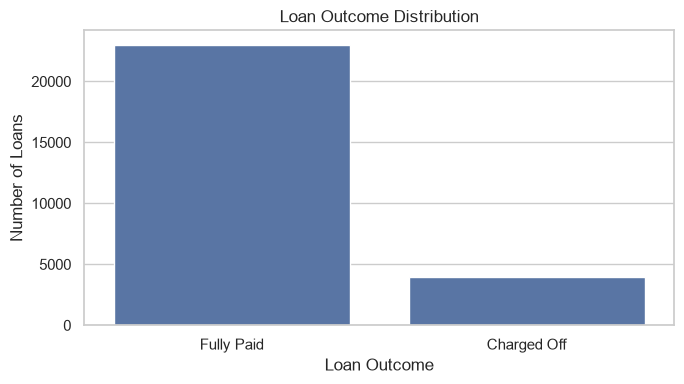

,Count,Percentage
loan_status,,
0,23026,85.27
1,3977,14.73


In [8]:
target_counts = y.value_counts().sort_index()

print("Default rate:", round(y.mean() * 100, 2), "%")

plt.figure(figsize=(7, 4))
sns.countplot(x=y)
plt.xticks([0, 1], ["Fully Paid", "Charged Off"])
plt.title("Loan Outcome Distribution")
plt.xlabel("Loan Outcome")
plt.ylabel("Number of Loans")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Count": target_counts,
    "Percentage": (target_counts / len(y) * 100).round(2)
}))

## 4. Exploratory Data Analysis (EDA)

#### Explore distributions, class balance, correlations, and default rates across selected categories. Use these plots to develop hypotheses and identify data-quality concerns.

### Explore numerical and categorical features

#### These visualizations summarize feature distributions, category frequencies, relationships with loan outcomes, and possible patterns in the default rate. They are exploratory findings, not proof of causation.

Numerical features: 27


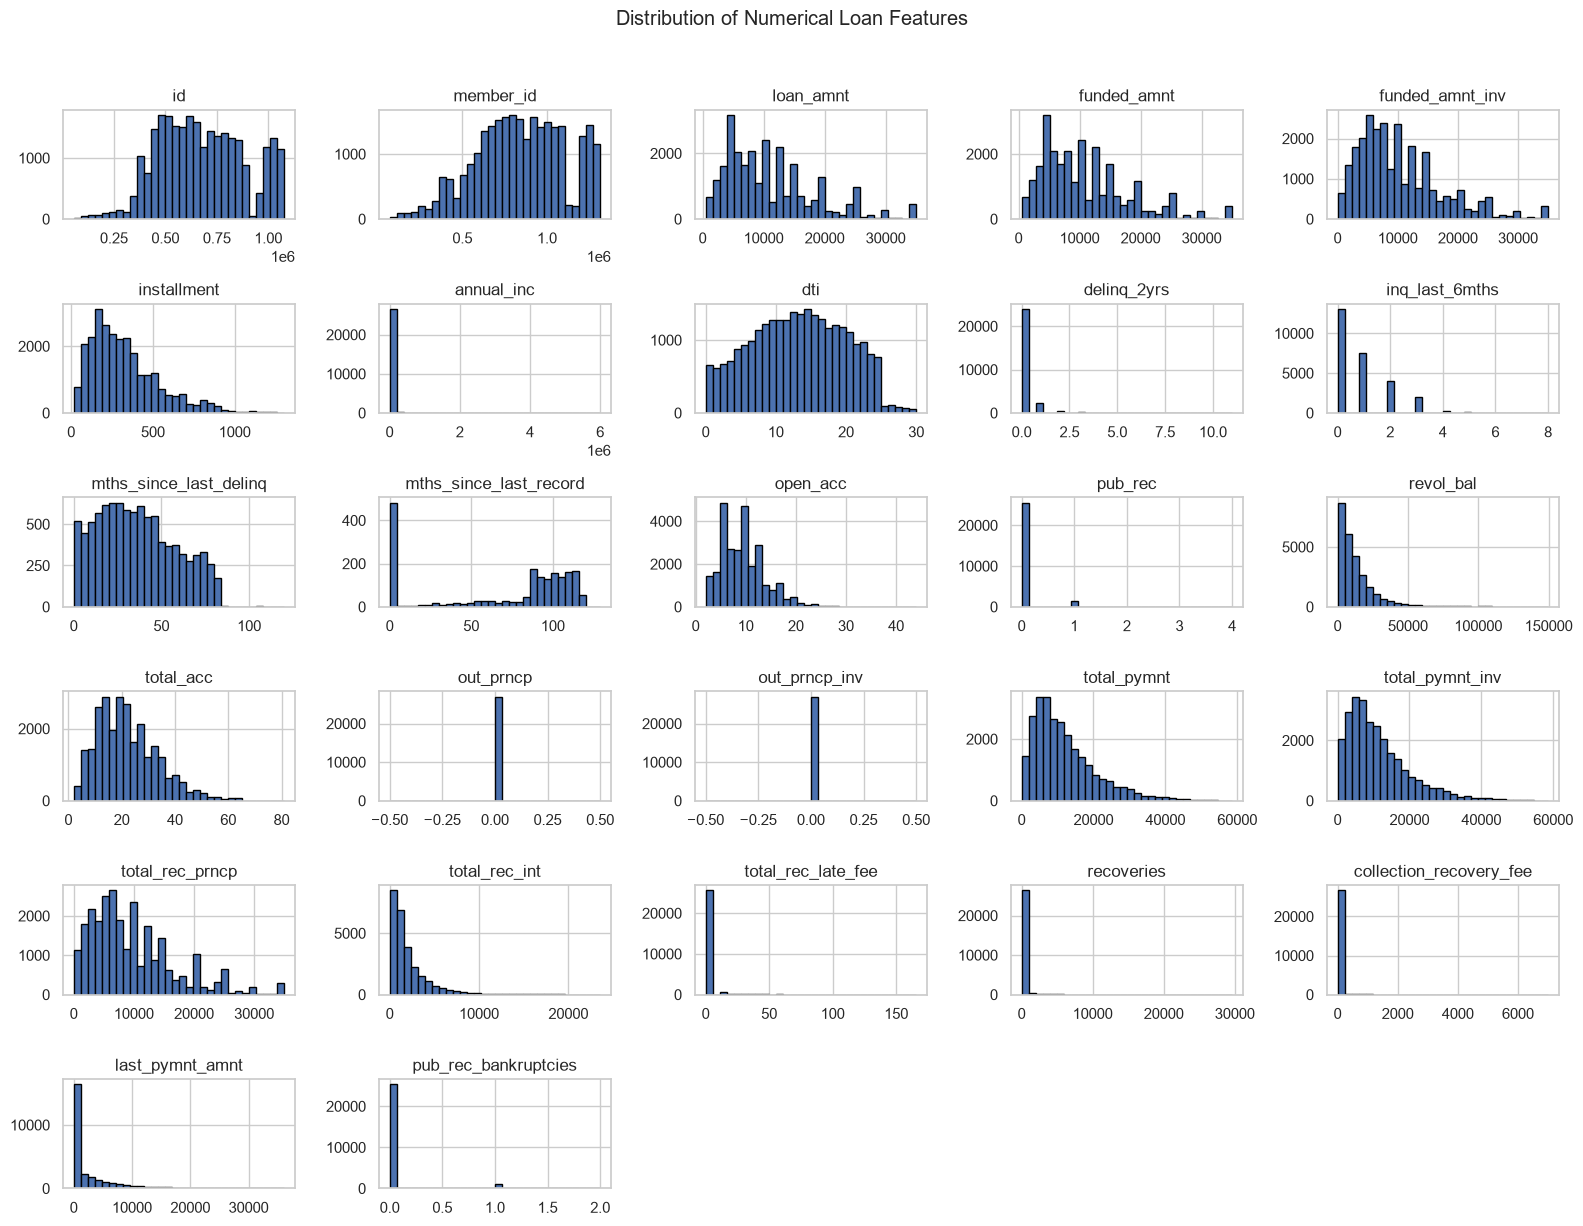

In [9]:
numeric_columns = X_raw.select_dtypes(include=np.number).columns.tolist()

print("Numerical features:", len(numeric_columns))

if numeric_columns:
    X_raw[numeric_columns].hist(
        figsize=(16, 12), bins=30, edgecolor="black"
    )
    plt.suptitle("Distribution of Numerical Loan Features", y=1.02)
    plt.tight_layout()
    plt.show()

In [10]:
categorical_columns = X_raw.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Categorical features:", len(categorical_columns))

for col in categorical_columns[:8]:
    print("\n", col)
    display(X_raw[col].value_counts(dropna=False).head(10).to_frame("Count"))

Categorical features: 19

 term


,Count
term,
36 months,20382
60 months,6621



 int_rate


,Count
int_rate,
10.99%,644
11.49%,568
7.51%,541
13.49%,526
7.88%,489
7.49%,450
9.99%,419
5.42%,412
11.71%,392



 grade


...

,Count
emp_length,
10+ years,6016
< 1 year,3133
2 years,2987
3 years,2819
4 years,2325
5 years,2249
1 year,2185
6 years,1494
7 years,1165



 home_ownership


,Count
home_ownership,
RENT,12864
MORTGAGE,11981
OWN,2094
OTHER,61
NONE,3



 verification_status


,Count
verification_status,
Not Verified,11684
Verified,8592
Source Verified,6727


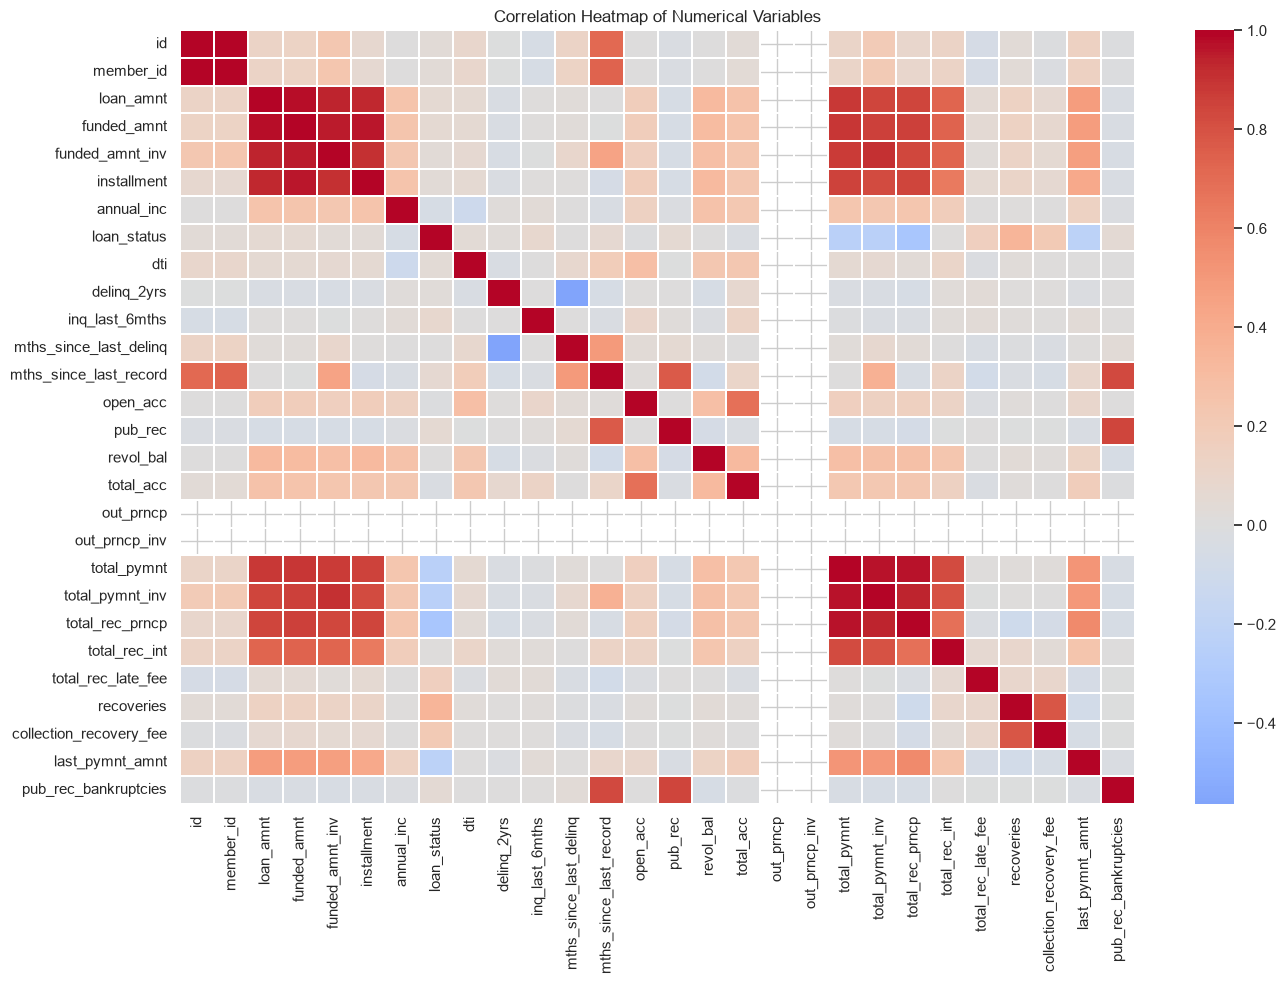

,Correlation with Loan Default
recoveries,0.347121
total_rec_prncp,-0.336436
total_pymnt,-0.238403
total_pymnt_inv,-0.236516
last_pymnt_amnt,-0.222977
collection_recovery_fee,0.210380
total_rec_late_fee,0.161950
inq_last_6mths,0.078920
mths_since_last_record,0.071591
loan_amnt,0.062101


In [11]:
numeric_eda = train.select_dtypes(include=np.number).copy()

if TARGET in numeric_eda.columns:
    numeric_eda[TARGET] = y

if numeric_eda.shape[1] >= 2:
    corr = numeric_eda.corr()

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        corr,
        cmap="coolwarm",
        center=0,
        linewidths=0.3
    )
    plt.title("Correlation Heatmap of Numerical Variables")
    plt.tight_layout()
    plt.show()

    if TARGET in corr.columns:
        display(
            corr[TARGET]
            .drop(TARGET)
            .sort_values(key=abs, ascending=False)
            .to_frame("Correlation with Loan Default")
        )


Default rate by term


,Default Rate,Loan Count
term,,
60 months,0.254795,6621
36 months,0.112354,20382


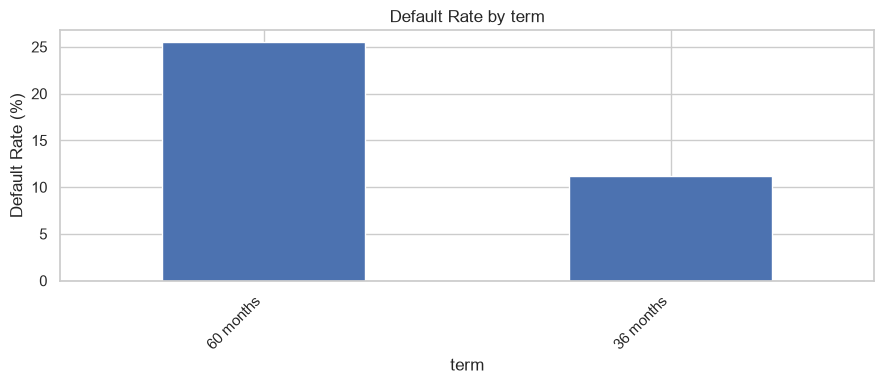


Default rate by int_rate


,Default Rate,Loan Count
int_rate,,
24.40%,1.000000,1
22.94%,1.000000,1
22.64%,1.000000,1
15.01%,1.000000,1
14.62%,1.000000,1
18.72%,1.000000,1
16.08%,1.000000,2
17.15%,1.000000,1
17.46%,1.000000,1


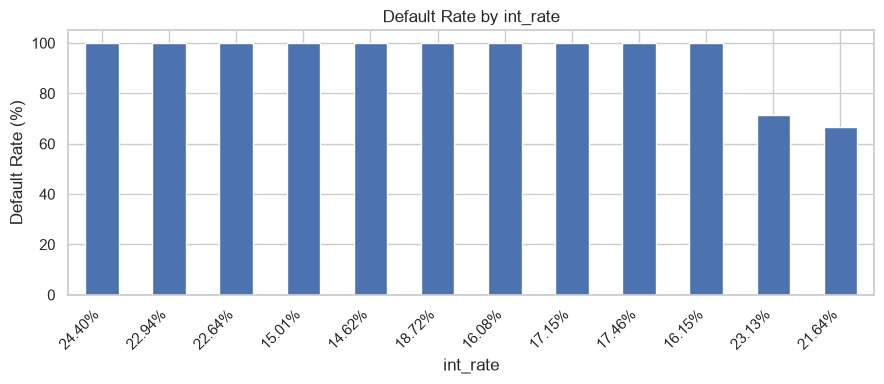


Default rate by grade


,Default Rate,Loan Count
grade,,
G,0.342466,219
F,0.315186,698
E,0.275027,1858
D,0.223386,3532
C,0.175316,5453
B,0.121504,8189
A,0.061100,7054


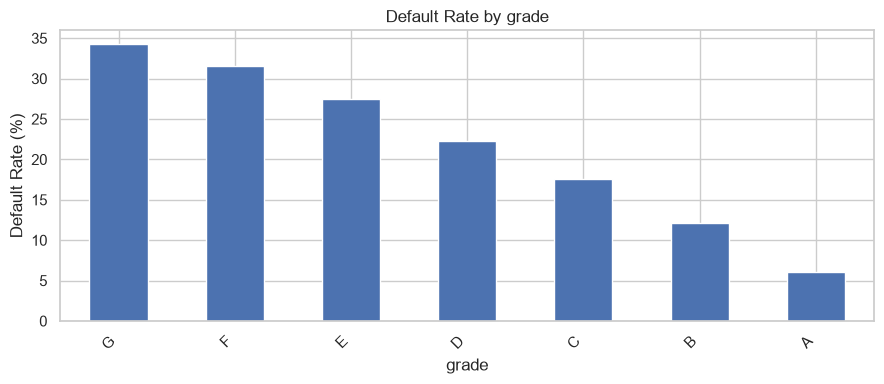


Default rate by sub_grade


,Default Rate,Loan Count
sub_grade,,
F5,0.447059,85
G3,0.407407,27
G5,0.363636,22
F4,0.363636,110
G2,0.357143,56
G1,0.350649,77
E5,0.297398,269
E2,0.293144,423
F2,0.292398,171


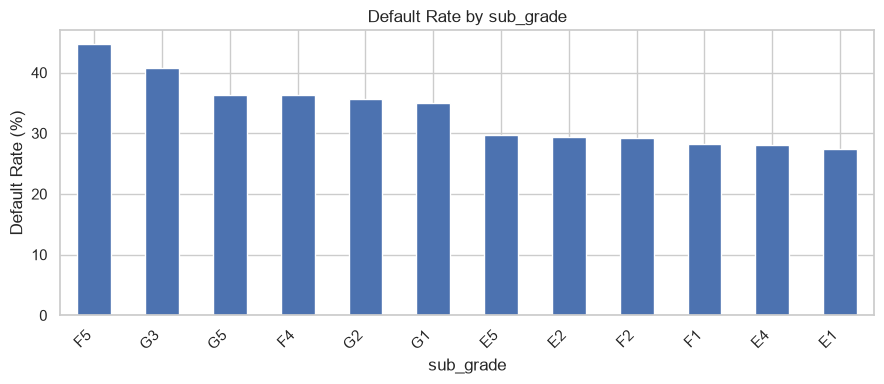


Default rate by emp_title


,Default Rate,Loan Count
emp_title,,
woodley building maintenance,1.0,1
2-J Supply Company,1.0,1
xotic deliveries,1.0,1
1 Cochran Hyundai,1.0,1
Charles Nelson,1.0,1
Charles Wright Academy,1.0,1
Charles river laboratories,1.0,1
Charlotte Mecklenburg Schools,1.0,1
Charlotte Russe INC,1.0,1


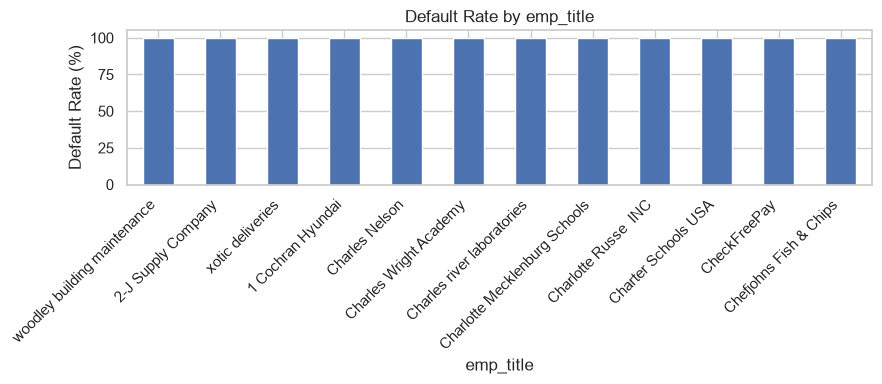

In [12]:
eda_data = X_raw.copy()
eda_data[TARGET] = y.values

for col in categorical_columns[:5]:
    summary = (
        eda_data.groupby(col, dropna=False)[TARGET]
        .agg(["mean", "count"])
        .rename(columns={"mean": "Default Rate", "count": "Loan Count"})
        .sort_values("Default Rate", ascending=False)
        .head(12)
    )

    print(f"\nDefault rate by {col}")
    display(summary)

    if not summary.empty:
        summary["Default Rate"].mul(100).plot(
            kind="bar", figsize=(9, 4)
        )
        plt.title(f"Default Rate by {col}")
        plt.ylabel("Default Rate (%)")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

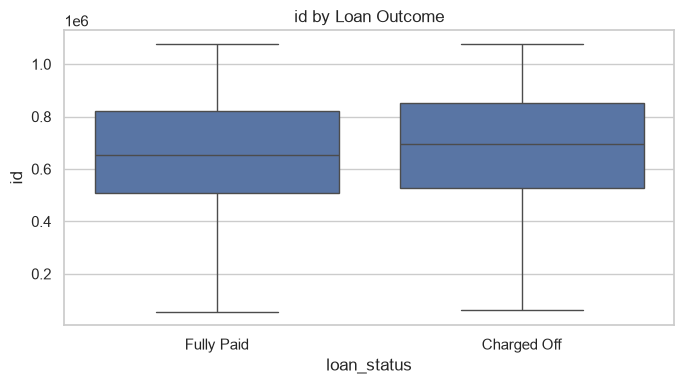

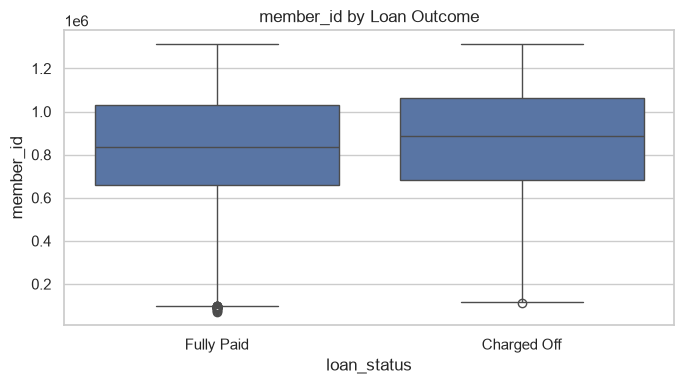

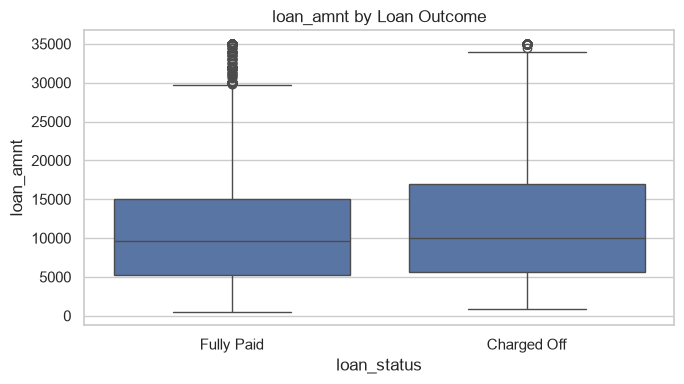

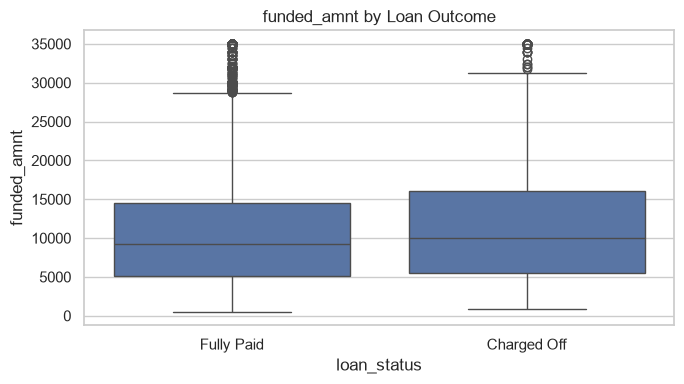

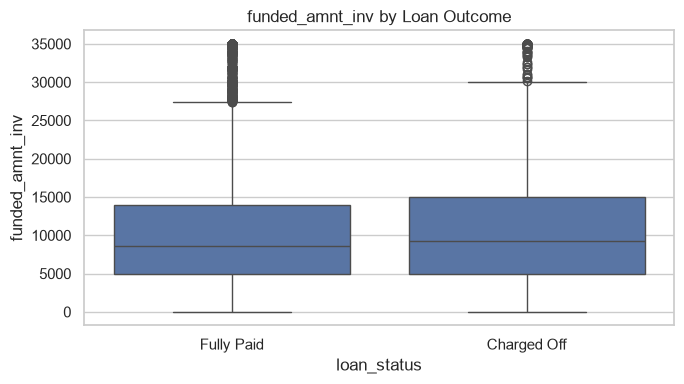

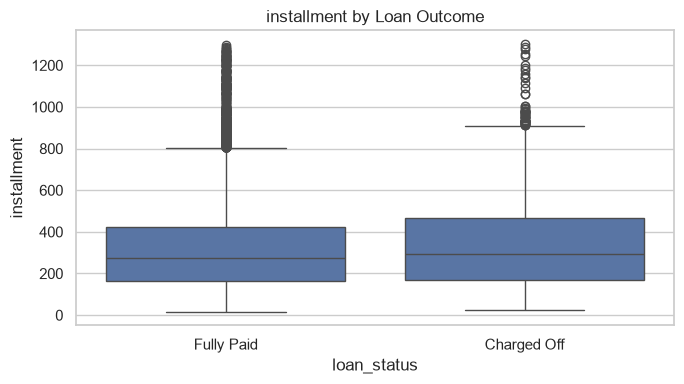

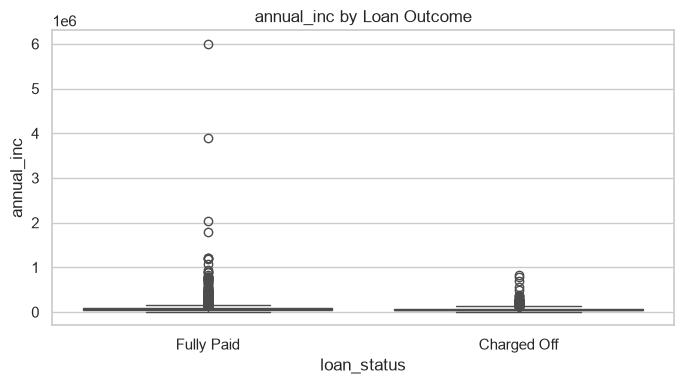

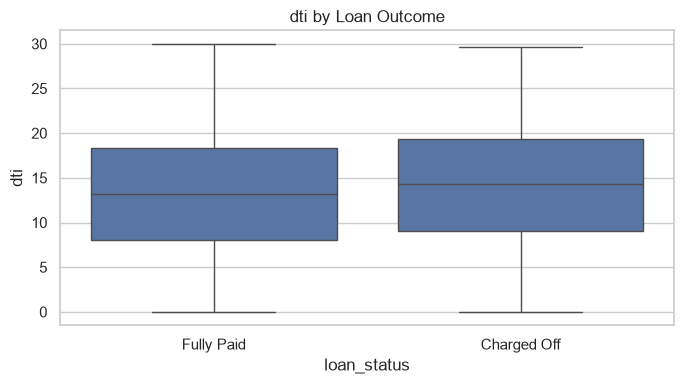

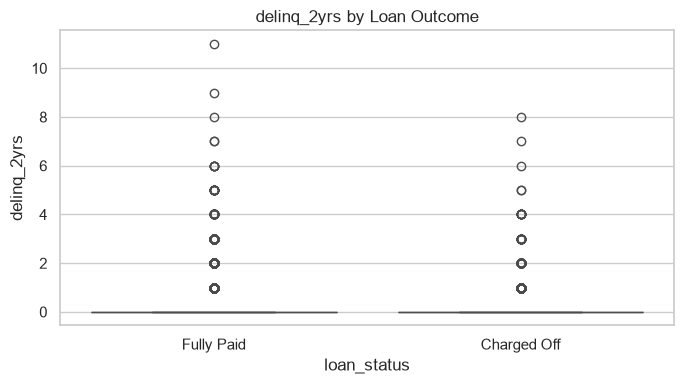

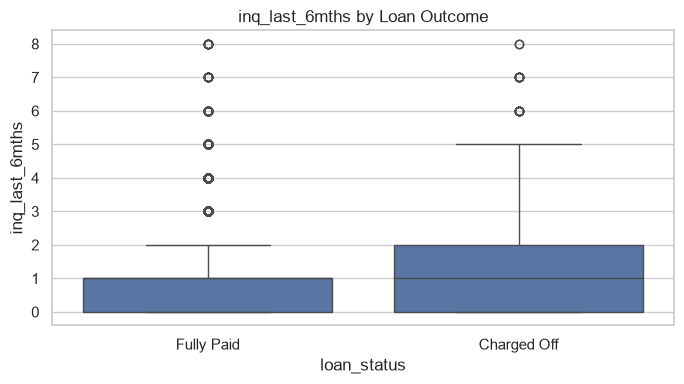

In [13]:
eda_numeric_cols = [
    col for col in numeric_columns
    if X_raw[col].nunique(dropna=True) > 2
][:10]

for col in eda_numeric_cols:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=eda_data, x=TARGET, y=col)
    plt.xticks([0, 1], ["Fully Paid", "Charged Off"])
    plt.title(f"{col} by Loan Outcome")
    plt.tight_layout()
    plt.show()

## 5. Statistical Validation

#### Mann–Whitney U tests compare numerical feature distributions between the two loan-outcome groups. Chi-square tests examine associations between categorical features and loan outcomes. Multiple-testing adjustment helps reduce false positives when many features are tested. Interpret statistical significance alongside sample size and business relevance.

In [14]:
from statsmodels.stats.multitest import multipletests

numeric_tests = []

for col in numeric_columns:
    a = X_raw.loc[y == 0, col].dropna()
    b = X_raw.loc[y == 1, col].dropna()

    if len(a) >= 2 and len(b) >= 2 and a.nunique() > 1 and b.nunique() > 1:
        stat, p = mannwhitneyu(a, b, alternative="two-sided")
        numeric_tests.append({
            "Feature": col,
            "Test": "Mann-Whitney U",
            "Statistic": stat,
            "P-Value": p,
            "Median Fully Paid": a.median(),
            "Median Charged Off": b.median()
        })

numeric_tests = pd.DataFrame(numeric_tests)

if not numeric_tests.empty:
    numeric_tests["Adjusted P-Value"] = multipletests(
        numeric_tests["P-Value"], method="fdr_bh"
    )[1]
    display(numeric_tests.sort_values("Adjusted P-Value"))
else:
    print("No eligible numerical features for statistical testing.")

,Feature,Test,Statistic,P-Value,Median Fully Paid,Median Charged Off,Adjusted P-Value
21,last_pymnt_amnt,Mann-Whitney U,69396874.0,0.000000e+00,874.960000,235.83,0.000000e+00
18,total_rec_prncp,Mann-Whitney U,76272741.5,0.000000e+00,9237.490000,2726.84,0.000000e+00
17,total_pymnt_inv,Mann-Whitney U,67598687.5,0.000000e+00,9995.115000,4357.04,0.000000e+00
16,total_pymnt,Mann-Whitney U,67648025.5,0.000000e+00,10704.516220,4868.88,0.000000e+00
20,total_rec_late_fee,Mann-Whitney U,40445217.0,9.133365e-203,0.000000,0.00,4.201348e-202
9,inq_last_6mths,Mann-Whitney U,40314404.5,1.377137e-38,1.000000,1.00,5.279027e-38
6,annual_inc,Mann-Whitney U,51213890.5,6.088571e-33,60000.000000,53000.00,2.000530e-32
13,pub_rec,Mann-Whitney U,44120256.0,6.216683e-21,0.000000,0.00,1.787296e-20
22,pub_rec_bankruptcies,Mann-Whitney U,42671666.0,6.959885e-17,0.000000,0.00,1.778637e-16
2,loan_amnt,Mann-Whitney U,42113572.0,5.609944e-16,9600.000000,10000.00,1.290287e-15


In [15]:
categorical_tests = []

for col in categorical_columns:
    table = pd.crosstab(
        X_raw[col].fillna("Missing"),
        y
    )

    if table.shape[0] >= 2 and table.shape[1] == 2:
        chi2, p, dof, expected = chi2_contingency(table)

        categorical_tests.append({
            "Feature": col,
            "Chi-Square": chi2,
            "Degrees of Freedom": dof,
            "P-Value": p,
            "Categories": table.shape[0]
        })

categorical_tests = pd.DataFrame(categorical_tests)

if not categorical_tests.empty:
    categorical_tests["Adjusted P-Value"] = multipletests(
        categorical_tests["P-Value"], method="fdr_bh"
    )[1]
    display(categorical_tests.sort_values("Adjusted P-Value"))
else:
    print("No eligible categorical features for statistical testing.")

,Feature,Chi-Square,Degrees of Freedom,P-Value,Categories,Adjusted P-Value
17,last_pymnt_d,1752.173026,101,3.709036e-299,102,7.047169e-298
2,grade,1122.057346,6,3.522341e-239,7,3.346224e-238
3,sub_grade,1208.456702,34,5.986797e-232,35,3.791638e-231
1,int_rate,1799.122884,367,3.825842e-187,368,1.817275e-186
0,term,806.250378,1,2.361147e-177,2,8.972358e-177
18,last_credit_pull_d,1131.455428,103,1.044678e-172,104,3.308148e-172
11,purpose,249.767983,13,7.153775e-46,14,1.941739e-45
7,verification_status,67.372139,2,2.345989e-15,3,5.571724e-15
8,issue_d,164.827440,54,3.800081e-13,55,8.022393e-13
16,revol_util,1381.650393,1052,2.632215e-11,1053,5.001209e-11


## 6. Feature Engineering and Leakage Prevention

#### Create useful date-derived features where possible and exclude fields that would not legitimately be known at prediction time.

### Remove leakage-prone information

#### Fields recorded after loan origination or during repayment can reveal the outcome and inflate model performance. These fields are excluded where identified. Date fields are converted into usable features where possible, while identifiers and unsuitable columns are handled during feature selection.

In [16]:
LEAKAGE_COLUMNS = [
    "out_prncp", "out_prncp_inv",
    "total_pymnt", "total_pymnt_inv",
    "total_rec_prncp", "total_rec_int",
    "total_rec_late_fee", "recoveries",
    "collection_recovery_fee", "last_pymnt_d",
    "last_pymnt_amnt", "last_credit_pull_d"
]

IDENTIFIER_COLUMNS = [
    "id", "member_id", "url", "desc",
    "emp_title", "title", "zip_code"
]

# Remove columns that are present and may be unsafe or unsuitable.
columns_to_drop = [
    c for c in LEAKAGE_COLUMNS + IDENTIFIER_COLUMNS
    if c in X_raw.columns
]

X = X_raw.drop(columns=columns_to_drop).copy()

print("Excluded columns:", columns_to_drop)
print("Remaining candidate features:", X.shape[1])

Excluded columns: ['out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'id', 'member_id', 'url', 'desc', 'emp_title', 'title', 'zip_code']
Remaining candidate features: 27


In [17]:
DATE_COLUMNS = ["issue_d", "earliest_cr_line"]

for col in DATE_COLUMNS:
    if col in X.columns:
        parsed = pd.to_datetime(X[col], format="%b-%Y", errors="coerce")

        if parsed.notna().mean() < 0.5:
            parsed = pd.to_datetime(X[col], errors="coerce")

        if parsed.notna().mean() >= 0.5:
            X[col + "_year"] = parsed.dt.year
            X[col + "_month"] = parsed.dt.month

            if col == "issue_d":
                X["_validation_date"] = parsed

            X = X.drop(columns=[col])

print("Feature engineering completed.")
display(X.head())

Feature engineering completed.


,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,...,pub_rec,revol_bal,revol_util,total_acc,pub_rec_bankruptcies,issue_d_year,issue_d_month,_validation_date,earliest_cr_line_year,earliest_cr_line_month
0,10000,10000,9975.0,36 months,13.23%,338.05,C,C1,4 years,RENT,...,0,10217,62.70%,14,0.0,1,7,1-07-10,1.0,9.0
1,14000,14000,13775.0,36 months,7.88%,437.94,A,A5,< 1 year,RENT,...,0,13307,28.80%,18,0.0,1,9,1-09-10,1.0,7.0
2,9475,9475,9475.0,36 months,8.94%,301.04,A,A5,9 years,OWN,...,0,7866,44.70%,17,0.0,1,11,1-11-09,1999.0,5.0
3,4000,4000,4000.0,36 months,7.29%,124.04,A,A4,10+ years,OWN,...,0,29358,69.10%,18,0.0,1,4,1-04-11,1997.0,12.0
4,3600,3600,3600.0,36 months,6.62%,110.54,A,A2,1 year,RENT,...,0,15502,70.10%,32,0.0,1,12,1-12-11,1999.0,4.0


## 7. Feature Selection and Validation Strategy

#### Remove unsuitable or redundant columns and establish a validation split that reflects the data's structure. Use a chronological split when a reliable date field supports it; otherwise, use stratified sampling.

### Prepare features and choose a validation split

#### Constant and extremely high-cardinality columns are removed. If a usable loan issue date is available, the notebook attempts a chronological split; otherwise, it uses a stratified random split. This keeps both outcome classes represented in the training and validation sets.

In [18]:
validation_date = None

if "_validation_date" in X.columns:
    validation_date = X["_validation_date"].copy()
    X = X.drop(columns=["_validation_date"])

# Remove columns with no useful variation.
constant_cols = [
    c for c in X.columns
    if X[c].nunique(dropna=False) <= 1
]
X = X.drop(columns=constant_cols)

# Drop extremely high-cardinality free-text columns if any remain.
high_cardinality_cols = [
    c for c in X.select_dtypes(include=["object", "string"]).columns
    if X[c].nunique(dropna=True) > 500
]
X = X.drop(columns=high_cardinality_cols)

print("Constant columns removed:", constant_cols)
print("High-cardinality columns removed:", high_cardinality_cols)
print("Final candidate features:", X.shape[1])

Constant columns removed: ['issue_d_year']
High-cardinality columns removed: ['revol_util']
Final candidate features: 27


In [19]:
if validation_date is not None and validation_date.notna().mean() >= 0.8:
    valid_date_rows = validation_date.notna()
    ordered_dates = validation_date[valid_date_rows].sort_values()

    cutoff = ordered_dates.iloc[int(len(ordered_dates) * 0.8)]

    train_mask = valid_date_rows & (validation_date < cutoff)
    valid_mask = valid_date_rows & (validation_date >= cutoff)

    if (
        train_mask.sum() > 0
        and valid_mask.sum() > 0
        and y[train_mask].nunique() == 2
        and y[valid_mask].nunique() == 2
    ):
        X_train, X_valid = X.loc[train_mask], X.loc[valid_mask]
        y_train, y_valid = y.loc[train_mask], y.loc[valid_mask]
        validation_method = "Chronological split"
    else:
        X_train, X_valid, y_train, y_valid = train_test_split(
            X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
        )
        validation_method = "Stratified random split (temporal split unsuitable)"
else:
    X_train, X_valid, y_train, y_valid = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
    )
    validation_method = "Stratified random split (no usable issue date)"

print("Validation method:", validation_method)
print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Training default rate:", round(y_train.mean() * 100, 2), "%")
print("Validation default rate:", round(y_valid.mean() * 100, 2), "%")

Validation method: Chronological split
Training rows: 21422
Validation rows: 5581
Training default rate: 14.56 %
Validation default rate: 15.37 %


## 8. Model Preprocessing

#### Numerical features are imputed with their median and scaled. Categorical features are imputed with their most frequent value and one-hot encoded. The transformations are placed in a pipeline so they are fitted on training data and consistently applied to validation and test data.

In [20]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = [
    c for c in X_train.columns
    if c not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 18
Categorical features: 9


## 9. Model Selection and Training

#### Three approaches are compared: a simple baseline, Logistic Regression, and Random Forest. Each model is combined with the preprocessing steps in a single pipeline, trained on the training split, and evaluated on the validation split. F1-score is used to rank the models, with precision, recall, ROC-AUC, and PR-AUC providing additional context.

In [21]:
models = {
    "Baseline": DummyClassifier(strategy="prior"),

    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=500,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=120,
        max_depth=18,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

fitted_models = {}
results = []
predictions = {}
probabilities = {}

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", classifier)
    ])

    pipeline.fit(X_train, y_train)

    pred = pipeline.predict(X_valid)

    if hasattr(pipeline, "predict_proba"):
        proba = pipeline.predict_proba(X_valid)[:, 1]
    else:
        proba = pred.astype(float)

    fitted_models[name] = pipeline
    predictions[name] = pred
    probabilities[name] = proba

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Precision": precision_score(y_valid, pred, zero_division=0),
        "Recall": recall_score(y_valid, pred, zero_division=0),
        "F1 Score": f1_score(y_valid, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_valid, proba),
        "PR-AUC": average_precision_score(y_valid, proba)
    })

results_df = pd.DataFrame(results).sort_values("F1 Score", ascending=False)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
2,Random Forest,0.7440,0.3067,0.5280,0.3880,0.7248,0.3356
1,Logistic Regression,0.6275,0.2523,0.7249,0.3744,0.7249,0.3181
0,Baseline,0.8463,0.0000,0.0000,0.0000,0.5000,0.1537


## 10. Cross-Validation

#### Stratified three-fold cross-validation estimates how consistently Logistic Regression and Random Forest perform across different subsets of the training data. Compare these averages with the single validation-split results to look for unstable performance.

In [22]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = {}

for name in ["Logistic Regression", "Random Forest"]:
    cv_pipeline = fitted_models[name]

    scores = cross_validate(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "precision": "precision",
            "recall": "recall",
            "roc_auc": "roc_auc",
            "average_precision": "average_precision"
        },
        n_jobs=1,
        return_train_score=False
    )

    cv_results[name] = {
        metric: scores[f"test_{metric}"].mean()
        for metric in [
            "f1", "precision", "recall", "roc_auc", "average_precision"
        ]
    }

cv_df = pd.DataFrame(cv_results).T
display(cv_df.round(4))

,f1,precision,recall,roc_auc,average_precision
Logistic Regression,0.3392,0.2350,0.6095,0.6858,0.2685
Random Forest,0.3343,0.2745,0.4277,0.6931,0.2639


## 11. Validation Results and Error Analysis

#### The model with the highest validation F1-score is selected for detailed evaluation. The classification report shows precision, recall, and F1-score for each class, while the confusion matrix summarizes correct and incorrect predictions.

Best validation model by F1-score: Random Forest

Classification report:
              precision    recall  f1-score   support

  Fully Paid       0.90      0.78      0.84      4723
 Charged Off       0.31      0.53      0.39       858

    accuracy                           0.74      5581
   macro avg       0.60      0.66      0.61      5581
weighted avg       0.81      0.74      0.77      5581



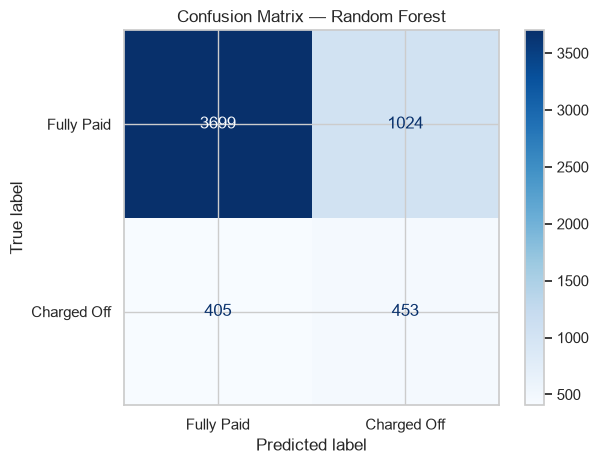

In [23]:
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

best_predictions = predictions[best_model_name]
best_probabilities = probabilities[best_model_name]

print("Best validation model by F1-score:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_valid,
    best_predictions,
    target_names=["Fully Paid", "Charged Off"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    best_predictions,
    display_labels=["Fully Paid", "Charged Off"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

### ROC Curve Comparison
#### The ROC curve shows the trade-off between true-positive rate and false-positive rate at different thresholds. A curve closer to the upper-left corner generally indicates stronger ranking performance.

<Figure size 700x500 with 0 Axes>

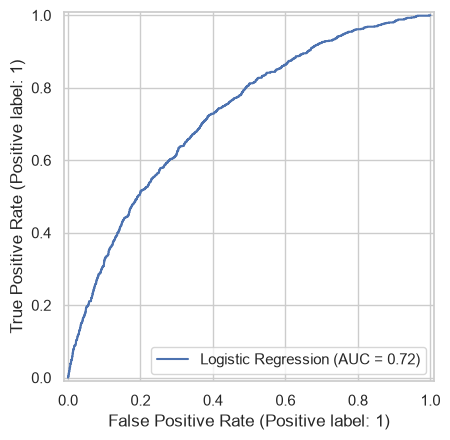

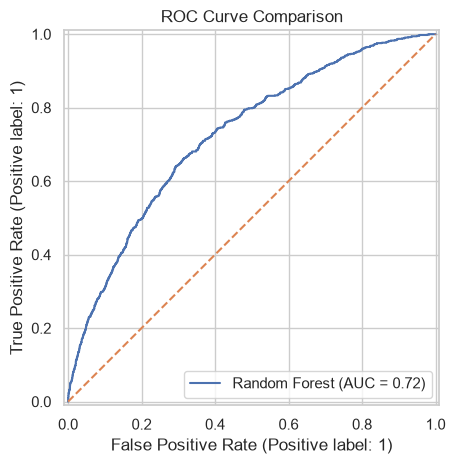

In [24]:
plt.figure(figsize=(7, 5))

for name in ["Logistic Regression", "Random Forest"]:
    RocCurveDisplay.from_predictions(
        y_valid,
        probabilities[name],
        name=name
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

<Figure size 700x500 with 0 Axes>

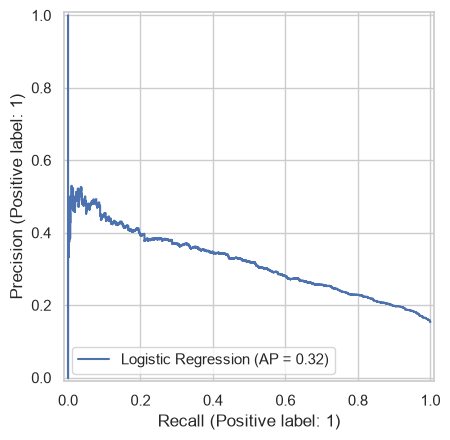

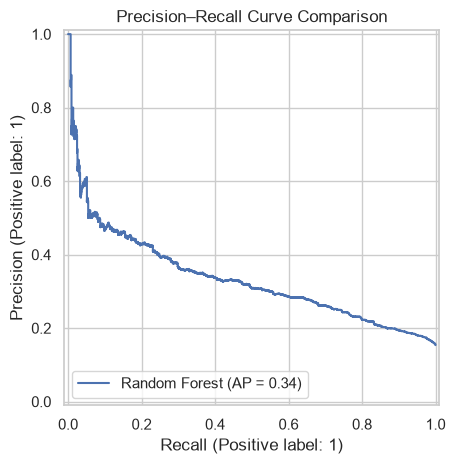

In [25]:
plt.figure(figsize=(7, 5))

for name in ["Logistic Regression", "Random Forest"]:
    PrecisionRecallDisplay.from_predictions(
        y_valid,
        probabilities[name],
        name=name
    )

plt.title("Precision–Recall Curve Comparison")
plt.tight_layout()
plt.show()

## 12. Model Interpretability

#### Random Forest feature importance gives an initial view of which transformed features contributed most to the fitted model. These scores describe model behavior, not causal effects, and correlated features can share or distort importance.

,Feature,Importance
4,numeric__annual_inc,0.060028
381,categorical__grade_A,0.058485
18,categorical__term_36 months,0.053387
19,categorical__term_60 months,0.047284
2,numeric__funded_amnt_inv,0.039803
5,numeric__dti,0.038136
12,numeric__revol_bal,0.037568
3,numeric__installment,0.035568
1,numeric__funded_amnt,0.032403
13,numeric__total_acc,0.031775


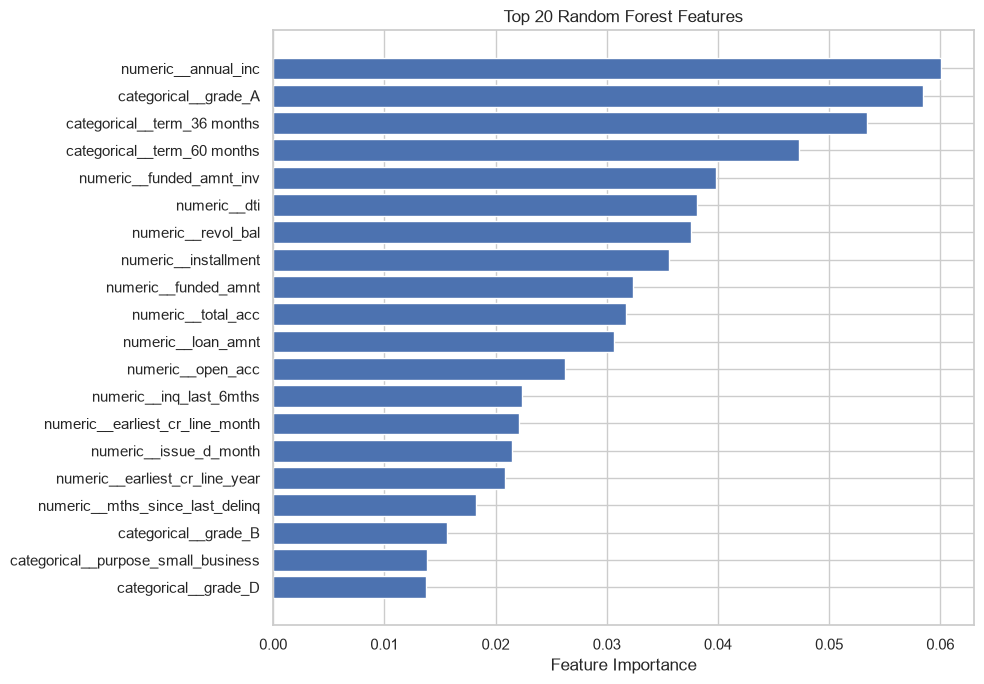

In [26]:
rf_pipeline = fitted_models["Random Forest"]

feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = rf_pipeline.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

top_features = importance_df.head(20).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 20 Random Forest Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

### Permutation Importance

#### Permutation importance measures how much validation performance changes when a feature is shuffled. Larger drops in F1-score suggest that the feature was more useful to the fitted model on this validation dataset.

In [27]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    scoring="f1",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

permutation_df = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance": permutation_result.importances_mean,
    "Std": permutation_result.importances_std
}).sort_values("Importance", ascending=False)

display(permutation_df.head(15))

,Feature,Importance,Std
3,term,0.086434,0.002427
6,grade,0.051537,0.005892
10,annual_inc,0.020169,0.000089
2,funded_amnt_inv,0.010275,0.004373
12,purpose,0.009247,0.002855
7,sub_grade,0.008500,0.001507
16,inq_last_6mths,0.006143,0.001361
21,revol_bal,0.005752,0.001570
8,emp_length,0.005693,0.000369
5,installment,0.004204,0.001126


## 13. Decision Threshold Analysis
#### The default probability threshold is varied to show how precision, recall, and F1-score change. The standard threshold of 0.50 is not automatically optimal; any threshold selected for deployment should reflect the lender's risk tolerance, operational capacity, and the relative costs of missed defaults and false positives.

,Threshold,Precision,Recall,F1 Score
0,0.20,0.1584,0.9977,0.2734
1,0.25,0.1667,0.9848,0.2851
2,0.30,0.1789,0.9580,0.3015
3,0.35,0.1925,0.9056,0.3175
4,0.40,0.2156,0.8322,0.3425
5,0.45,0.2576,0.7110,0.3782
6,0.50,0.3067,0.5280,0.3880
7,0.55,0.3440,0.3753,0.3590
8,0.60,0.4055,0.2424,0.3034
9,0.65,0.4783,0.0897,0.1511


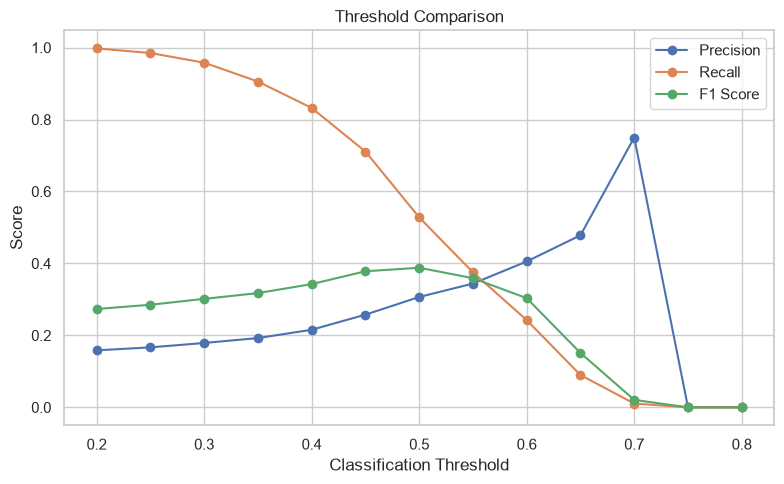

In [28]:
threshold_results = []

for threshold in np.arange(0.2, 0.81, 0.05):
    pred_at_threshold = (
        best_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_valid, pred_at_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, pred_at_threshold, zero_division=0
        ),
        "F1 Score": f1_score(
            y_valid, pred_at_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

plt.figure(figsize=(8, 5))
for metric in ["Precision", "Recall", "F1 Score"]:
    plt.plot(
        threshold_df["Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Comparison")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Temporal Analysis

#### Where issue-date information is available, monthly loan volumes and default rates are examined for potential changes over time. Temporal patterns can reflect changes in borrower mix, underwriting policy, or economic conditions; they should be investigated before drawing conclusions.

,Issue Month,mean,count,Default Rate (%)
0,1-01,0.140579,1693,14.057885
1,1-02,0.126309,1623,12.630930
2,1-03,0.129167,1920,12.916667
3,1-04,0.131197,1997,13.119680
4,1-05,0.155046,2051,15.504632
5,1-06,0.155946,2161,15.594632
6,1-07,0.142258,2383,14.225766
7,1-08,0.143583,2361,14.358323
8,1-09,0.156806,2417,15.680596
9,1-10,0.159970,2663,15.996996


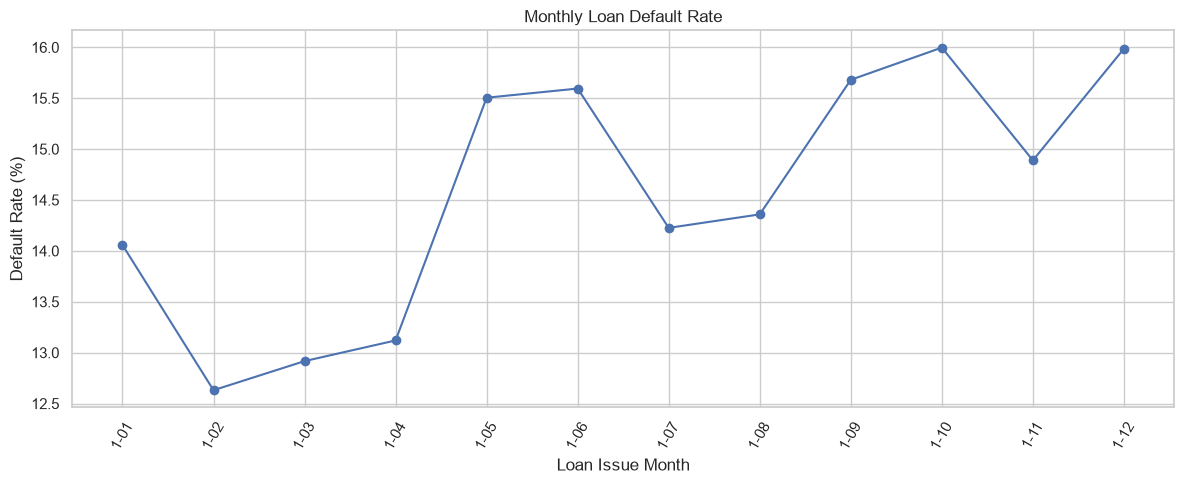

In [29]:
if "issue_d" in train.columns:
    issue_dates = pd.to_datetime(
        train["issue_d"], format="%b-%Y", errors="coerce"
    )

    if issue_dates.notna().mean() < 0.5:
        issue_dates = pd.to_datetime(
            train["issue_d"], errors="coerce"
        )

    temporal_df = pd.DataFrame({
        "Issue Date": issue_dates,
        "Default": y.values
    }).dropna()

    if not temporal_df.empty:
        temporal_df["Issue Month"] = (
            temporal_df["Issue Date"].dt.to_period("M").astype(str)
        )

        monthly_default = (
            temporal_df.groupby("Issue Month")["Default"]
            .agg(["mean", "count"])
            .reset_index()
        )

        monthly_default["Default Rate (%)"] = (
            monthly_default["mean"] * 100
        )

        display(monthly_default.tail(20))

        plt.figure(figsize=(12, 5))
        plt.plot(
            monthly_default["Issue Month"],
            monthly_default["Default Rate (%)"],
            marker="o"
        )
        plt.title("Monthly Loan Default Rate")
        plt.xlabel("Loan Issue Month")
        plt.ylabel("Default Rate (%)")
        plt.xticks(rotation=60)
        plt.tight_layout()
        plt.show()
    else:
        print("Issue dates could not be parsed for temporal analysis.")
else:
    print("No issue date available; temporal analysis is not possible.")

## 15. Final Model and Reproducible Artifact
#### After validation, the selected pipeline is refitted on the available labeled training data and saved as a serialized artifact. Saving the complete pipeline preserves preprocessing and model steps together for consistent future predictions.

In [30]:
final_model = fitted_models[best_model_name]

final_model.fit(X, y)

joblib.dump(
    {
        "model": final_model,
        "features": X.columns.tolist(),
        "model_name": best_model_name
    },
    "loan_default_model.pkl"
)

print("Final model trained and saved.")
print("Saved file: loan_default_model.pkl")
print("Selected model:", best_model_name)

Final model trained and saved.
Saved file: loan_default_model.pkl
Selected model: Random Forest


### Generate test-set predictions

#### If the competition test dataset is available, apply the same feature preparation and saved pipeline to it. The generated CSV is intended for the competition workflow; verify its required column names and row count against the sample submission format before submitting.

In [31]:
if test is not None:
    X_test = test.drop(
        columns=[TARGET], errors="ignore"
    ).copy()

    X_test = X_test.drop(
        columns=[
            c for c in columns_to_drop
            if c in X_test.columns
        ],
        errors="ignore"
    )

    for col in DATE_COLUMNS:
        if col in X_test.columns:
            parsed = pd.to_datetime(
                X_test[col], format="%b-%Y", errors="coerce"
            )

            if parsed.notna().mean() < 0.5:
                parsed = pd.to_datetime(
                    X_test[col], errors="coerce"
                )

            if parsed.notna().mean() >= 0.5:
                X_test[col + "_year"] = parsed.dt.year
                X_test[col + "_month"] = parsed.dt.month

            X_test = X_test.drop(columns=[col])

    X_test = X_test.drop(
        columns=["_validation_date"], errors="ignore"
    )

    X_test = X_test.drop(
        columns=constant_cols + high_cardinality_cols,
        errors="ignore"
    )

    X_test = X_test.reindex(columns=X.columns)

    test_predictions = final_model.predict(X_test)

    submission = pd.DataFrame({
        "id": (
            test["id"].values
            if "id" in test.columns
            else np.arange(len(test))
        ),
        "loan_status": test_predictions.astype(int)
    })

    if sample_submission is not None:
        if list(sample_submission.columns) == list(submission.columns):
            submission["id"] = sample_submission["id"].values

    submission.to_csv("loan_default_predictions.csv", index=False)

    print("Test predictions generated:", len(submission))
    display(submission.head())
    print("Saved: loan_default_predictions.csv")
else:
    print("Test CSV not found. Skipping competition predictions.")

Test predictions generated: 11574


,id,loan_status
0,213846,0
1,608415,0
2,454264,0
3,1066768,0
4,882910,1


Saved: loan_default_predictions.csv


## 16. Project Summary and Business Recommendations

#### Summarize the dataset, target default rate, selected features, validation approach, model comparison, and most important risk indicators. Recommendations should be treated as decision support rather than automatic loan approval or rejection.

## Business Recommendations and Actionable Insights

### 1. Using Default Risk Predictions

The Loan Default Risk Prediction model can help lenders identify applicants who may have a higher probability of defaulting on their loans. The predicted risk score can be used as a decision-support tool to prioritize applications for further review.

### 2. Prioritizing Manual Reviews

- **High-risk applicants:** Applications with higher predicted default probabilities can be prioritized for detailed manual review. Lenders can verify income, existing debt obligations, repayment history, and other relevant information.
- **Medium-risk applicants:** These applications may require additional document verification or a more detailed affordability assessment.
- **Low-risk applicants:** These applications may be processed through the lender's standard assessment procedure, subject to all required eligibility checks.

Risk categories should be determined using a suitable probability threshold based on validation results and the lender's business requirements.

### 3. Understanding False Positives and Missed Defaults

Model predictions are not always correct, so lenders should consider two important types of errors:

- **False positives:** Applicants predicted to default who would actually repay their loans. Too many false positives can lead to unnecessary manual reviews, increased operational costs, and potentially unfair treatment of creditworthy applicants.
- **False negatives:** Applicants predicted not to default who eventually default. These missed defaults can expose lenders to financial losses.

The model's precision, recall, and F1-score help evaluate this trade-off. A higher recall can help identify more actual defaulters, while precision indicates how many applicants flagged as potential defaulters actually belong to the default class.

### 4. Choosing an Appropriate Decision Threshold

The default probability threshold should be selected according to the cost of missed defaults, the cost of manual reviews, and the lender's risk tolerance. A lower threshold may identify more potential defaulters but can also increase false positives. A higher threshold may reduce unnecessary reviews but miss more actual defaulters.

The threshold should be evaluated on validation data before being used in practice.

### 5. Responsible Use of the Model

The model should support, rather than replace, human judgment. Loan decisions should also consider relevant financial information, applicable lending regulations, fairness, and the applicant's complete circumstances. The model's performance should be monitored regularly as lending conditions and applicant characteristics change.

### Conclusion

The Loan Default Risk Prediction model can help lenders prioritize manual reviews, allocate resources more efficiently, and identify potential credit risks. However, its predictions are estimates rather than guarantees. Combining model outputs with human review, appropriate decision thresholds, and ongoing performance monitoring can support more informed lending decisions.

In [32]:
print("=" * 50)
print("LOAN DEFAULT RISK PREDICTION - PROJECT SUMMARY")
print("=" * 50)

print("Training records:", len(train))
print("Candidate features:", X.shape[1])
print("Default rate:", round(y.mean() * 100, 2), "%")
print("Validation strategy:", validation_method)
print("Selected model:", best_model_name)

display(results_df.round(4))

print("Model saved: loan_default_model.pkl")

if test is not None:
    print("Predictions saved: loan_default_predictions.csv")

LOAN DEFAULT RISK PREDICTION - PROJECT SUMMARY
Training records: 27003
Candidate features: 27
Default rate: 14.73 %
Validation strategy: Chronological split
Selected model: Random Forest


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
2,Random Forest,0.7440,0.3067,0.5280,0.3880,0.7248,0.3356
1,Logistic Regression,0.6275,0.2523,0.7249,0.3744,0.7249,0.3181
0,Baseline,0.8463,0.0000,0.0000,0.0000,0.5000,0.1537


Model saved: loan_default_model.pkl
Predictions saved: loan_default_predictions.csv


## Conclusion

#### This project developed an end-to-end machine learning workflow for loan default risk prediction. It included data inspection, cleaning, exploratory data analysis, statistical validation, feature engineering, leakage prevention, model comparison, validation, feature importance analysis, and business recommendations.

#### The models were evaluated using classification metrics, with particular attention to F1-score because it is the metric used by the Kaggle competition. The selected model and preprocessing pipeline were saved for reproducibility, and predictions were generated for the competition test dataset when available.

#### The analysis demonstrates how machine learning can support credit-risk assessment. Before real-world deployment, further validation, fairness assessment, monitoring, and business review would be required.